# Vector Quantization and Image Compression

![](img/banner.png)

Computer Science Dept, Ferdowsi University of Mashhad

## Where this page sits

Section 14.3.9 of {cite}`hastie2009esl` uses K-means for something that has
nothing to do with clustering as a descriptive tool: **compressing an image**.
The idea is old and has its own name — *vector quantization*, VQ — and it is the
reason the supervised method of the previous chapter is called Learning Vector
Quantization. The two lessons are kept apart, because this one has no labels at
all and is measured in bits and decibels instead of error rates.

### What you should be able to do at the end

* describe the encoder and the decoder of a VQ codec, and say what a codeword
  and a codebook are;
* compute the **rate** of a VQ scheme from the block size and the codebook size,
  and the **distortion** from the reconstruction error;
* explain why the same K-means code can be a clustering method or a compressor,
  depending only on what the vectors are;
* read a rate/distortion curve and say what the extra bits buy.

## 1. The idea

Cut the image into small blocks. Treat each block as a **point** in
`R^(bs*bs)` — a 2×2 block is a point in `R^4`. Run K-means on the collection of
all blocks of the image. Then:

* **encoding**: store, for every block, the *index* of its closest centre;
* **decoding**: rebuild the image by replacing every block with that centre.

The centres are called **codewords**, their set is the **codebook**, and the
whole thing is *lossy*: the rebuilt image is not the original. The book's example
is a 1024×1024 photograph (8 bits per pixel, 1 MB); with `K = 200` codewords it
needs 0.239 of the storage, and with `K = 4` only 0.0625 of it.

With `bs x bs` blocks and `K` codewords, each block costs `log2(K)` bits, so

$$
\text{rate} = \frac{\log_2 K}{bs^2}\ \text{bits per pixel},
\qquad
\frac{\text{storage}}{\text{original}} = \frac{\text{rate}}{8},
$$

and the distortion is the mean squared error between the original and the
rebuilt image. The book reports `D = 0.89` at `K = 200` and `D = 16.95` at
`K = 4` (gray levels on the 0–255 scale).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import data
from skimage.util import view_as_blocks

%matplotlib inline

A 256×256 grayscale test image, 8 bits per pixel, is enough to reproduce the
experiment: the arithmetic of the rate does not depend on the picture, and the
smaller image keeps the notebook fast. (The book uses a 1024×1024 portrait; the
same code runs on it and takes `K = 200` codewords for 1.91 bits per pixel.)

shape: (256, 256) | dtype: uint8 | range: 3 - 255


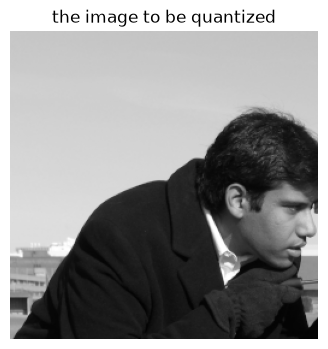

In [2]:
img = data.camera()[:256, :256]      # 256 x 256, gray levels 0..255
print("shape:", img.shape, "| dtype:", img.dtype, "| range:", img.min(), "-", img.max())

plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("the image to be quantized")
plt.axis("off");

## 2. Blocks become vectors

`view_as_blocks` cuts the image without copying overlapping pixels; reshaping the
result gives one row per block. Note what has been gained: the picture is now a
cloud of points in `R^4`, and K-means does not know — or care — that they came
from an image.

In [3]:
def blocks_of(img, bs):
    """Cut the image into bs x bs blocks; every block becomes a row vector."""
    h, w = img.shape
    grid = view_as_blocks(img, (bs, bs))            # (h/bs, w/bs, bs, bs)
    return grid.reshape(-1, bs * bs).astype(float)


blocks = blocks_of(img, 2)
print("pixels:", img.size, "| blocks:", blocks.shape[0], "| vector length:", blocks.shape[1])
blocks[:3]

pixels: 65536 | blocks: 16384 | vector length: 4


array([[200., 200., 200., 199.],
       [200., 200., 199., 200.],
       [199., 200., 199., 200.]])

## 3. Encoding and decoding in one function

`KMeans.fit` is the *encoder*: it builds the codebook and returns the index of
the nearest codeword for every block (`labels_`). Indexing the codebook with
those labels and folding the vectors back into blocks is the *decoder*.

In [4]:
def vq_round_trip(img, bs, K, n_init=3, seed=0):
    """Encode with K-means on blocks, then decode; return the rebuilt image and its cost."""
    blocks = blocks_of(img, bs)
    km = KMeans(n_clusters=K, n_init=n_init, max_iter=100, random_state=seed).fit(blocks)

    rec_blocks = km.cluster_centers_[km.labels_]          # decoding
    h, w = img.shape
    rec = rec_blocks.reshape(h // bs, w // bs, bs, bs).transpose(0, 2, 1, 3).reshape(h, w)

    rate = np.log2(K) / (bs * bs)                         # bits per pixel, fixed-length code
    mse = ((img - rec) ** 2).mean()
    return dict(rec=rec, rate=rate, mse=mse,
                psnr=10 * np.log10(255 ** 2 / mse), labels=km.labels_)


print(vq_round_trip(img, 2, 16)["rate"], "bits per pixel for 2x2 blocks, K=16")

1.0 bits per pixel for 2x2 blocks, K=16


## 4. The rate/distortion table

Each row is one codec: a block size (`2 x 2` everywhere here) and a codebook size.
`K` grows geometrically, the rate grows logarithmically — that is the whole
economy of the method.

In [5]:
results = {}
print(f"{'K':>5}{'bits/block':>12}{'rate (bpp)':>12}{'storage':>9}{'MSE':>8}{'PSNR dB':>9}")
for K in (2, 4, 16, 64, 200):
    r = vq_round_trip(img, 2, K)
    results[K] = r
    print(f"{K:>5}{np.log2(K):>12.0f}{r['rate']:>12.2f}{r['rate'] / 8:>9.3f}"
          f"{r['mse']:>8.2f}{r['psnr']:>9.2f}")

    K  bits/block  rate (bpp)  storage     MSE  PSNR dB


    2           1        0.25    0.031  489.17    21.24


    4           2        0.50    0.062  169.17    25.85


   16           4        1.00    0.125   49.73    31.16


   64           6        1.50    0.188   19.36    35.26


  200           8        1.91    0.239    8.53    38.82


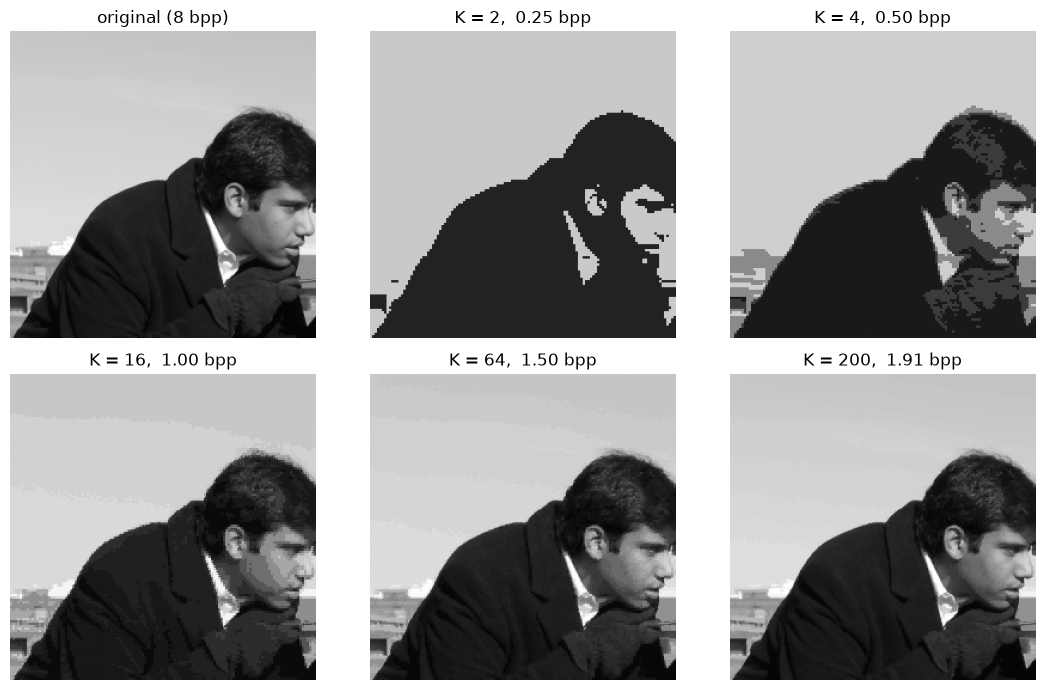

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("original (8 bpp)")
for ax, K in zip(axes.ravel()[1:], (2, 4, 16, 64, 200)):
    ax.imshow(results[K]["rec"], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"K = {K},  {results[K]['rate']:.2f} bpp")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout();

At `0.50` bits per pixel — one sixteenth of the original — the picture is
already recognisable, which is the point of the method. At `0.06` bits per pixel
the blocks win, and the image is a mosaic of 2×2 tiles: sixteen times fewer
codewords than tiles means that neighbouring tiles are forced to share a value.

The same information, plotted as a curve, is the object that compression
engineers compare codecs with.

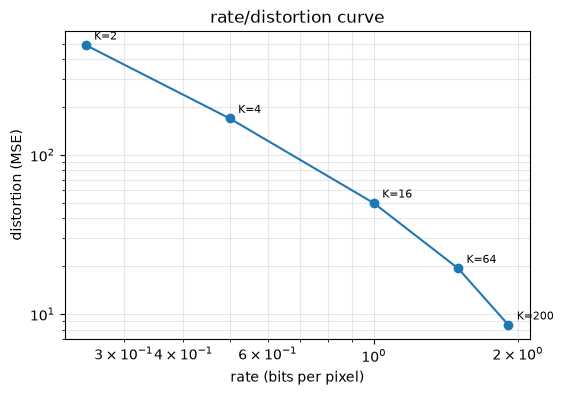

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog([results[K]["rate"] for K in results], [results[K]["mse"] for K in results], "o-")
for K in results:
    ax.annotate(f"K={K}", (results[K]["rate"], results[K]["mse"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("rate (bits per pixel)")
ax.set_ylabel("distortion (MSE)")
ax.set_title("rate/distortion curve")
ax.grid(alpha=0.3, which="both");

## 5. Fixed-length or entropy coding?

`log2(K)` bits per block assumes every codeword is equally likely. It is not:
several codewords (plain white, a few grays) are used by thousands of blocks while
others appear a handful of times. Coding the indices with a length proportional
to `-log2(p)` instead — Shannon's construction — gives the entropy rate

$$
\text{rate}_{\text{ent}} = \frac{1}{bs^2}\ \Big(-\sum_\ell p_\ell \log_2 p_\ell\Big),
$$

which is always below the fixed-length rate. The book reports 1.42 and 0.39
bits per pixel for the same two codebooks, against 1.91 and 0.50.

In [8]:
def entropy_rate(labels, bs):
    p = np.bincount(labels) / len(labels)
    p = p[p > 0]
    return -(p * np.log2(p)).sum() / (bs * bs)


print(f"{'K':>5}{'fixed-length':>15}{'entropy code':>15}")
for K, r in results.items():
    print(f"{K:>5}{r['rate']:>15.2f}{entropy_rate(r['labels'], 2):>15.2f}")

    K   fixed-length   entropy code
    2           0.25           0.25
    4           0.50           0.40
   16           1.00           0.82
   64           1.50           1.11
  200           1.91           1.45


## 6. The other knob: block size

The rate formula has `bs` in the denominator twice over, so large blocks are
cheap per pixel — and expensive in fidelity, because a block is forced to become
one of `K` average patches. With the codebook held at `K = 16` and the block size
doubling, the rate falls by a factor of four each time:

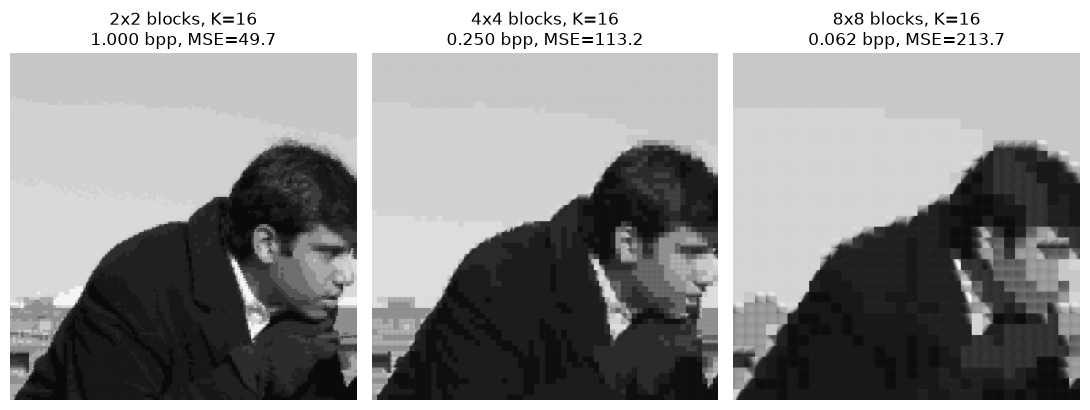

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, bs in zip(axes, (2, 4, 8)):
    r = vq_round_trip(img, bs, 16)
    ax.imshow(r["rec"], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{bs}x{bs} blocks, K=16\n{r['rate']:.3f} bpp, MSE={r['mse']:.1f}")
    ax.axis("off")
plt.tight_layout();

The 8×8 version is cheapest and worst: the tiles are visible as squares, and
edges of objects become staircases. Real codecs therefore use larger codebooks
with small blocks, or transform the block before quantizing (the JPEG family),
which is the same trade-off expressed in a different basis.

## Summary

* Vector quantization replaces each block by the **index of the nearest
  codeword**; the set of codewords is the codebook.
* The encoder is `KMeans.fit`, the decoder is `codebook[labels]`; the algorithm
  is Lloyd's, and nothing in it knows that the vectors came from an image.
* The rate is `log2(K)/bs^2` bits per pixel, and the distortion is the MSE of the
  reconstruction; the pair traces a rate/distortion curve.
* Fixed-length coding wastes bits when the codeword distribution is skewed;
  entropy coding of the same indices lowers the rate without touching the
  distortion.
* Block size and codebook size are two ways to spend the same bit budget; the
  visible artifacts (2×2 tiles, staircase edges) tell you which one is being
  spent.
* This is where the name Learning Vector Quantization comes from — but VQ itself
  uses no labels, and is the subject of [a page of its own](Vector-Quantization.ipynb).

## Exercises

1. Reproduce the book's setting: take a 1024×1024 image, 2×2 blocks,
   `K = 200`, and check the storage fraction `0.239`. Where does the remaining
   difference from the ideal come from?
2. Compute the *variable-length* rate of a codebook built on 4×4 blocks and
   compare it with the fixed-length rate. Which codewords dominate?
3. Replace K-means by a random codebook (sample `K` blocks and use them as
   centres). How much worse is the distortion at the same rate, and why?
4. Quantize the *color* image: blocks of shape `(2, 2, 3)`, vectors in `R^12`.
   Compare rate and visual quality with the gray version.
5. Plot distortion against rate for `bs = 2, 4` and `K = 2..256` on one axes. Is
   one block size uniformly better, or do the curves cross?
6. What would a *lossless* version of block clustering look like? (Hint: the
   book reports that entropy coding the original image reaches 4.48 bits per
   pixel, so lossless block coding can aim for that.)

## Sources

* The method, the worked example and the reported numbers (1.91 and 0.50 bits per
  pixel, `D = 0.89` and `16.95`, entropy rates 1.42 and 0.39): §14.3.9 of
  {cite}`hastie2009esl`, pp. 514–516. Figures here are produced by the code above
  on a different test image, so the distortions are not directly comparable with
  the book's.
* Gersho and Gray, *Vector Quantization and Signal Compression*, is the reference
  the book cites for the method itself.
* The supervised variant of the same idea — where the prototypes carry class
  labels — is [Learning Vector Quantization](Learning-Vector-Quantization.ipynb).